In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Path dataset mentah (sudah ada, ini punyamu)
df = pd.read_csv('/content/drive/MyDrive/Datasetretention/online_retail_II.csv')

# Path folder OUTPUT - tempat semua hasil (CSV cleaning, cohort, dll) disimpan
DRIVE_PATH = '/content/drive/MyDrive/Ecommerce_Retention_Project'

# **Step 1 Data Understanding**

In [4]:
df.head()
#menampilkan 5 data teratas

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


In [5]:
df.shape
#menampilkan jumlah baris dan kolom

(1048575, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1048575 non-null  object 
 1   StockCode    1048575 non-null  object 
 2   Description  1044203 non-null  object 
 3   Quantity     1048575 non-null  int64  
 4   InvoiceDate  1048575 non-null  object 
 5   Price        1048575 non-null  float64
 6   Customer ID  811893 non-null   float64
 7   Country      1048575 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 64.0+ MB


In [7]:
df.isnull().sum()
#digunakan untuk menghitung banyaknya the number of missing value (NaN)

,0
Invoice,0
StockCode,0
Description,4372
Quantity,0
InvoiceDate,0
Price,0
Customer ID,236682
Country,0


In [8]:
df.describe()

,Quantity,Price,Customer ID
count,1.048575e+06,1.048575e+06,811893.000000
mean,9.957525e+00,4.627346e+00,15324.712265
std,1.335187e+02,1.228024e+02,1697.033034
min,-7.421500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13971.000000
50%,3.000000e+00,2.100000e+00,15260.000000
75%,1.000000e+01,4.150000e+00,16795.000000
max,7.421500e+04,3.897000e+04,18287.000000


In [9]:
df[['Quantity', 'Price']].describe()

,Quantity,Price
count,1.048575e+06,1.048575e+06
mean,9.957525e+00,4.627346e+00
std,1.335187e+02,1.228024e+02
min,-7.421500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,7.421500e+04,3.897000e+04


In [10]:
df.duplicated().sum()

np.int64(34150)

In [11]:
df[df.duplicated(keep=False)].sort_values('Invoice').head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,12/1/2009 11:34,1.95,16329.0,United Kingdom
390,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,12/1/2009 11:34,2.55,16329.0,United Kingdom
388,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,12/1/2009 11:34,2.55,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,12/1/2009 11:34,0.65,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,12/1/2009 11:34,1.95,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom


In [12]:
df[df['Invoice'].astype(str).str.startswith('C')]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,12/1/2009 10:33,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,12/1/2009 10:33,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,12/1/2009 10:33,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,12/1/2009 10:33,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,12/1/2009 10:33,2.95,16321.0,Australia
...,...,...,...,...,...,...,...,...
1046566,C580313,22649,STRAWBERRY FAIRY CAKE TEAPOT,-3,12/2/2011 15:10,4.95,12668.0,Germany
1046567,C580313,22419,LIPSTICK PEN RED,-6,12/2/2011 15:10,0.42,12668.0,Germany
1046568,C580313,22303,COFFEE MUG APPLES DESIGN,-2,12/2/2011 15:10,2.55,12668.0,Germany
1046569,C580313,21232,STRAWBERRY CERAMIC TRINKET POT,-3,12/2/2011 15:10,1.25,12668.0,Germany


In [13]:
df['InvoiceDate']

,InvoiceDate
0,12/1/2009 7:45
1,12/1/2009 7:45
2,12/1/2009 7:45
3,12/1/2009 7:45
4,12/1/2009 7:45
...,...
1048570,12/4/2011 13:00
1048571,12/4/2011 13:00
1048572,12/4/2011 13:15
1048573,12/4/2011 13:15


In [14]:
df['Customer ID'].nunique(), df['Invoice'].nunique(), df['StockCode'].nunique()

(5924, 52961, 5304)

# **Step 2 Data Cleaning**

In [15]:
df_clean = df.copy()
#Copy dari data asli agar data asli tetap aman

In [16]:
# InvoiceDate masih string -> ubah ke datetime supaya bisa dipakai untuk cohort/retention
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Bersihkan spasi berlebih di Description dan StockCode
df_clean['Description'] = df_clean['Description'].str.strip()
df_clean['StockCode'] = df_clean['StockCode'].str.strip()

print(df_clean.dtypes)

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


In [17]:
# Simpan versi lengkap SEBELUM drop, untuk laporan revenue total perusahaan nanti
df_full = df_clean.copy()

# Baris tanpa Customer ID menyumbang ~13.5% total revenue -> jangan langsung dibuang tanpa catatan
missing_cust_revenue = (df_full[df_full['Customer ID'].isna()]['Quantity'] *
                         df_full[df_full['Customer ID'].isna()]['Price']).sum()
total_revenue = (df_full['Quantity'] * df_full['Price']).sum()
print(f"Revenue tanpa Customer ID: {missing_cust_revenue:,.2f} ({missing_cust_revenue/total_revenue:.1%} dari total)")

# Baru drop untuk keperluan cohort/retention (WAJIB, karena butuh ID pelanggan)
df_clean = df_clean.dropna(subset=['Customer ID']).copy()
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)

Revenue tanpa Customer ID: 2,568,394.89 (13.5% dari total)


In [18]:
#Hapus duplikat
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
after = len(df_clean)
print(f"Duplikat dibuang: {before - after}")

Duplikat dibuang: 26294


In [19]:
#Pisahkan transaksi cancel/return
# Invoice yang diawali 'C' = cancelled order
df_clean['is_cancelled'] = df_clean['Invoice'].astype(str).str.startswith('C')

df_cancelled = df_clean[df_clean['is_cancelled']].copy()
df_clean = df_clean[~df_clean['is_cancelled']].copy()

# Simpan sebagai file terpisah untuk dipakai lagi nanti di Step 8 tanpa perlu re-run semua cleaning
df_cancelled.to_csv(f'{DRIVE_PATH}/cancelled_transactions.csv', index=False)

print(f"Transaksi cancel disimpan: {len(df_cancelled)} baris -> cancelled_transactions.csv")
print(f"Total nilai transaksi cancel: {(df_cancelled['Quantity']*df_cancelled['Price']).sum():,.2f}")

Transaksi cancel disimpan: 18160 baris -> cancelled_transactions.csv
Total nilai transaksi cancel: -910,546.38


In [20]:
import re
#Filter kode non-produk (lebih lengkap berbaris pola)

# List eksplisit kode admin/biaya yang diketahui
known_non_product = ['POST', 'DOT', 'D', 'C2', 'M', 'BANK CHARGES', 'AMAZONFEE',
                      'PADS', 'CRUK', 'ADJUST', 'ADJUST2', 'S', 'B']

# StockCode produk asli polanya: 5 digit angka + opsional 1 huruf (mis. 85123A)
# Apapun di luar pola ini (gift_xxx, DCGSxxxx, dll) kemungkinan bukan produk fisik reguler
def is_valid_product_code(code):
    code = str(code).strip().upper()
    if code in known_non_product:
        return False
    return bool(re.match(r'^\d{5}[A-Z]?$', code))

before = len(df_clean)
df_clean['StockCode_clean'] = df_clean['StockCode'].str.strip().str.upper()
mask_valid = df_clean['StockCode_clean'].apply(is_valid_product_code)

# Tampilkan dulu apa saja yang akan terbuang, sebelum benar-benar difilter
print("Kode yang akan dibuang (bukan produk reguler):")
print(df_clean.loc[~mask_valid, 'StockCode_clean'].value_counts().head(20))

df_clean = df_clean[mask_valid].drop(columns=['StockCode_clean'])
print(f"\nBaris dibuang: {before - len(df_clean)}")

Kode yang akan dibuang (bukan produk reguler):
StockCode_clean
POST            1765
15056BL          794
M                682
C2               247
79323LP          159
79323GR           76
ADJUST            32
BANK CHARGES      30
PADS              18
DOT               15
TEST001           11
D                  5
ADJUST2            3
SP1002             2
TEST002            1
Name: count, dtype: int64

Baris dibuang: 3840


In [21]:
df.value_counts()

Invoice  StockCode  Description                          Quantity  InvoiceDate       Price  Customer ID  Country       
555524   22698      PINK REGENCY TEACUP AND SAUCER       1         6/5/2011 11:37    2.95   16923.0      United Kingdom    20
         22697      GREEN REGENCY TEACUP AND SAUCER      1         6/5/2011 11:37    2.95   16923.0      United Kingdom    12
537224   70007      HI TEC ALPINE HAND WARMER            1         12/5/2010 16:24   1.65   13174.0      United Kingdom    10
572861   22775      PURPLE DRAWERKNOB ACRYLIC EDWARDIAN  12        10/26/2011 12:46  1.25   14102.0      United Kingdom     8
537051   22730      ALARM CLOCK BAKELIKE IVORY           1         12/5/2010 11:12   3.75   15708.0      United Kingdom     6
                                                                                                                           ..
522663   22297      HEART IVORY TRELLIS SMALL            48        9/16/2010 10:56   1.25   13113.0      United Kingdom     1
         22423      REGENCY CAKESTAND 3 TIER             16        9/16/2010 10:56   10.95  13113.0      United Kingdom     1
         22427      ENAMEL FLOWER JUG CREAM              3         9/16/2010 10:56   5.95   13113.0      United Kingdom     1
         37448      CERAMIC CAKE DESIGN SPOTTED MUG      10        9/16/2010 10:56   1.49   13113.0      United Kingdom     1
522651   84992      72 SWEETHEART FAIRY CAKE CASES       24        9/16/2010 10:51   0.55   12433.0      Norway             1
Name: count, Length: 785599, dtype: int64

In [22]:
#Filter Quantity dan Price tidak valid
# Investigasi dulu: Quantity negatif yang lolos dari filter cancel di Sel 4
neg_qty_check = df_clean[df_clean['Quantity'] < 0]
print(f"Baris Quantity negatif tersisa (non-cancel): {len(neg_qty_check)}")
print(neg_qty_check[['Invoice','StockCode','Description','Quantity','Price']].head(10))

Baris Quantity negatif tersisa (non-cancel): 0
Empty DataFrame
Columns: [Invoice, StockCode, Description, Quantity, Price]
Index: []


In [23]:
df_clean[df_clean['Quantity']<0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancelled


In [24]:
#Cek dan tangani Outlier ekstrem
df_clean[['Quantity', 'Price']].describe()

# Lihat top 10 transaksi dengan Quantity/Price tertinggi -> valid bulk order atau error input?
df_clean.nlargest(10, 'Quantity')[['Invoice','StockCode','Description','Quantity','Price','Customer ID']]

,Invoice,StockCode,Description,Quantity,Price,Customer ID
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940


In [25]:
before = len(df_clean)
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean = df_clean[df_clean['Price'] > 0]
print(f"Baris dibuang: {before - len(df_clean)}")

Baris dibuang: 60


In [26]:
#Outlier:CAP, bukan di hapus
print("Quantity - persentil ekstrem:")
print(df_clean['Quantity'].quantile([0.95, 0.99, 0.995, 0.999, 1.0]))
print("\nPrice - persentil ekstrem:")
print(df_clean['Price'].quantile([0.95, 0.99, 0.995, 0.999, 1.0]))

# Buat kolom Revenue dulu sebelum keputusan cap
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

# Simpan flag, JANGAN hapus baris - supaya cohort/retention (berbasis ada/tidaknya transaksi & total revenue)
# tetap dihitung, tapi kamu bisa exclude flag ini khusus saat bikin chart rata-rata (AOV, dsb)
q99 = df_clean['Quantity'].quantile(0.99)
p99 = df_clean['Price'].quantile(0.99)
df_clean['is_outlier'] = (df_clean['Quantity'] > q99) | (df_clean['Price'] > p99)

print(f"\nJumlah baris ditandai outlier: {df_clean['is_outlier'].sum()} ({df_clean['is_outlier'].mean():.1%})")

Quantity - persentil ekstrem:
0.950       36.0
0.990      144.0
0.995      216.0
0.999      576.0
1.000    74215.0
Name: Quantity, dtype: float64

Price - persentil ekstrem:
0.950      8.50
0.990     12.75
0.995     16.95
0.999     34.95
1.000    649.50
Name: Price, dtype: float64

Jumlah baris ditandai outlier: 12509 (1.6%)


In [27]:
print("Shape akhir:", df_clean.shape)
print("\nMissing values:\n", df_clean.isna().sum())
print("\nUnique customers:", df_clean['Customer ID'].nunique())
print("Unique invoices:", df_clean['Invoice'].nunique())
print("Date range:", df_clean['InvoiceDate'].min(), "-", df_clean['InvoiceDate'].max())

Shape akhir: (763539, 11)

Missing values:
 Invoice         0
StockCode       0
Description     0
Quantity        0
InvoiceDate     0
Price           0
Customer ID     0
Country         0
is_cancelled    0
Revenue         0
is_outlier      0
dtype: int64

Unique customers: 5834
Unique invoices: 36083
Date range: 2009-12-01 07:45:00 - 2011-12-04 13:15:00


# **Step 3 Revenue & Transaction Table**

In [28]:
# Batasi data hanya sampai 30 Nov 2011, karena Des 2011 cuma 4 hari (data tidak lengkap)
# dan akan membuat cohort bulan terakhir terlihat seolah retensinya anjlok padahal cuma bulan yang belum penuh
cutoff_date = pd.Timestamp('2011-11-30 23:59:59')

before = len(df_clean)
df_clean = df_clean[df_clean['InvoiceDate'] <= cutoff_date].copy()
print(f"Baris dibuang (setelah cutoff): {before - len(df_clean)}")
print(f"Rentang tanggal final: {df_clean['InvoiceDate'].min()} - {df_clean['InvoiceDate'].max()}")

# Revenue per baris
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

# Agregasi ke level Invoice
invoice_table = df_clean.groupby('Invoice').agg(
    Customer_ID=('Customer ID', 'first'),
    InvoiceDate=('InvoiceDate', 'first'),
    Total_Items=('Quantity', 'sum'),
    N_Products=('StockCode', 'nunique'),
    Revenue=('Revenue', 'sum'),
    Country=('Country', 'first')
).reset_index()

print(f"\nJumlah invoice: {len(invoice_table)}")
invoice_table.head()

Baris dibuang (setelah cutoff): 4954
Rentang tanggal final: 2009-12-01 07:45:00 - 2011-11-30 17:37:00

Jumlah invoice: 35817


,Invoice,Customer_ID,InvoiceDate,Total_Items,N_Products,Revenue,Country
0,489434,13085,2009-12-01 07:45:00,166,8,505.30,United Kingdom
1,489435,13085,2009-12-01 07:46:00,60,4,145.80,United Kingdom
2,489436,13078,2009-12-01 09:06:00,193,19,630.33,United Kingdom
3,489437,15362,2009-12-01 09:08:00,145,23,310.75,United Kingdom
4,489438,18102,2009-12-01 09:24:00,826,17,2286.24,United Kingdom


In [29]:
customer_table = invoice_table.groupby('Customer_ID').agg(
    First_Purchase=('InvoiceDate', 'min'),
    Last_Purchase=('InvoiceDate', 'max'),
    N_Transactions=('Invoice', 'nunique'),
    Total_Revenue=('Revenue', 'sum'),
    Avg_Order_Value=('Revenue', 'mean'),
    Country=('Country', 'first')
).reset_index()

# Tambahan berguna: sudah berapa lama jadi customer (dalam hari)
customer_table['Customer_Lifespan_Days'] = (
    customer_table['Last_Purchase'] - customer_table['First_Purchase']
).dt.days

customer_table.to_csv(f'{DRIVE_PATH}/customer_table.csv', index=False)

print(f"Jumlah unique customer: {len(customer_table)}")
customer_table.sort_values('Total_Revenue', ascending=False).head(10)

Jumlah unique customer: 5824


,Customer_ID,First_Purchase,Last_Purchase,N_Transactions,Total_Revenue,Avg_Order_Value,Country,Customer_Lifespan_Days
5638,18102,2009-12-01 09:24:00,2011-11-28 12:55:00,142,564101.50,3972.545775,United Kingdom,727
2248,14646,2009-12-02 16:52:00,2011-11-23 11:06:00,142,515023.50,3626.926056,Netherlands,720
1765,14156,2009-12-01 12:30:00,2011-11-30 10:54:00,144,300845.98,2089.208194,EIRE,728
2505,14911,2009-12-01 11:41:00,2011-11-30 15:08:00,364,264344.47,726.221071,EIRE,729
5002,17450,2010-09-27 16:59:00,2011-11-29 09:56:00,50,243221.85,4864.437000,United Kingdom,427
1309,13694,2009-12-04 15:26:00,2011-11-14 11:11:00,140,192081.73,1372.012357,United Kingdom,709
5061,17511,2009-12-02 10:52:00,2011-11-23 10:31:00,58,164753.55,2840.578448,United Kingdom,720
66,12415,2010-06-30 08:30:00,2011-11-15 14:22:00,24,144033.37,6001.390417,Australia,503
4248,16684,2009-12-07 12:56:00,2011-11-28 15:35:00,54,136085.79,2520.107222,United Kingdom,721
2652,15061,2009-12-01 12:18:00,2011-11-29 10:52:00,126,122491.71,972.156429,United Kingdom,727


In [30]:
# Total revenue harus konsisten antara line-item, invoice table, dan customer table
print("Total Revenue (line-item):", df_clean['Revenue'].sum())
print("Total Revenue (invoice table):", invoice_table['Revenue'].sum())
print("Total Revenue (customer table):", customer_table['Total_Revenue'].sum())

# Distribusi jumlah transaksi per customer -> gambaran awal retensi
print("\nDistribusi N_Transactions per customer:")
print(customer_table['N_Transactions'].describe())
print("\n% customer yang cuma belanja 1x (berpotensi churn):",
      f"{(customer_table['N_Transactions']==1).mean():.1%}")

Total Revenue (line-item): 16499466.629999999
Total Revenue (invoice table): 16499466.63
Total Revenue (customer table): 16499466.629999999

Distribusi N_Transactions per customer:
count    5824.000000
mean        6.149897
std        12.519730
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       364.000000
Name: N_Transactions, dtype: float64

% customer yang cuma belanja 1x (berpotensi churn): 28.3%


In [31]:
customer_table.nlargest(5, 'N_Transactions')[['Customer_ID','N_Transactions','Total_Revenue','Country']]

,Customer_ID,N_Transactions,Total_Revenue,Country
2505,14911,364,264344.47,EIRE
386,12748,313,47973.79,United Kingdom
5384,17841,207,65912.81,United Kingdom
2900,15311,204,112792.97,United Kingdom
722,13089,199,108342.89,United Kingdom


In [32]:
customer_table.nlargest(5, 'N_Transactions')[['Customer_ID','N_Transactions','Total_Revenue','Country']]

,Customer_ID,N_Transactions,Total_Revenue,Country
2505,14911,364,264344.47,EIRE
386,12748,313,47973.79,United Kingdom
5384,17841,207,65912.81,United Kingdom
2900,15311,204,112792.97,United Kingdom
722,13089,199,108342.89,United Kingdom


In [33]:
invoice_table.to_csv('invoice_table.csv', index=False)
customer_table.to_csv('customer_table.csv', index=False)

print("Tersimpan: invoice_table.csv & customer_table.csv")

Tersimpan: invoice_table.csv & customer_table.csv


# **STEP 4 CUSTOMER COHORT**

In [34]:
# =========================================================
# STEP 4 — CUSTOMER COHORT
# Dibangun ulang dari df_clean setiap kali dijalankan,
# supaya aman di-run berkali-kali tanpa duplikat kolom.
# =========================================================

# 1. Buat ulang invoice_table dari df_clean (bukan menimpa invoice_table lama)
invoice_table = df_clean.groupby('Invoice').agg(
    Customer_ID=('Customer ID', 'first'),
    InvoiceDate=('InvoiceDate', 'first'),
    Total_Items=('Quantity', 'sum'),
    N_Products=('StockCode', 'nunique'),
    Revenue=('Revenue', 'sum'),
    Country=('Country', 'first')
).reset_index()

# 2. InvoiceMonth: bulan terjadinya tiap transaksi
invoice_table['InvoiceMonth'] = invoice_table['InvoiceDate'].dt.to_period('M')

# 3. CohortMonth: bulan pertama kali TIAP CUSTOMER belanja
cohort_month_map = (
    invoice_table.groupby('Customer_ID')['InvoiceMonth']
    .min()
    .rename('CohortMonth')
)
invoice_table = invoice_table.merge(cohort_month_map, on='Customer_ID', how='left')

# 4. CohortIndex: bulan ke-berapa sejak first purchase
invoice_table['CohortIndex'] = (
    (invoice_table['InvoiceMonth'].dt.year - invoice_table['CohortMonth'].dt.year) * 12
    + (invoice_table['InvoiceMonth'].dt.month - invoice_table['CohortMonth'].dt.month)
    + 1
)

invoice_table.to_csv(f'{DRIVE_PATH}/invoice_table_with_cohort.csv', index=False)

print("Kolom invoice_table:", list(invoice_table.columns))
print(f"\nJumlah invoice: {len(invoice_table)}")
print(f"Rentang CohortIndex: {invoice_table['CohortIndex'].min()} - {invoice_table['CohortIndex'].max()}")
invoice_table[['Invoice','Customer_ID','InvoiceMonth','CohortMonth','CohortIndex']].head()

Kolom invoice_table: ['Invoice', 'Customer_ID', 'InvoiceDate', 'Total_Items', 'N_Products', 'Revenue', 'Country', 'InvoiceMonth', 'CohortMonth', 'CohortIndex']

Jumlah invoice: 35817
Rentang CohortIndex: 1 - 24


,Invoice,Customer_ID,InvoiceMonth,CohortMonth,CohortIndex
0,489434,13085,2009-12,2009-12,1
1,489435,13085,2009-12,2009-12,1
2,489436,13078,2009-12,2009-12,1
3,489437,15362,2009-12,2009-12,1
4,489438,18102,2009-12,2009-12,1


Jumlah customer baru per cohort bulanan:
CohortMonth
2009-12    951
2010-01    368
2010-02    375
2010-03    441
2010-04    294
2010-05    255
2010-06    267
2010-07    185
2010-08    163
2010-09    239
2010-10    375
2010-11    326
2010-12     76
2011-01     72
2011-02    125
2011-03    179
2011-04    106
2011-05    111
2011-06    108
2011-07    101
2011-08    107
2011-09    188
2011-10    221
2011-11    191
Freq: M, Name: Customer_ID, dtype: int64


<Axes: title={'center': 'Jumlah Customer Baru per Cohort Bulanan'}, xlabel='CohortMonth'>

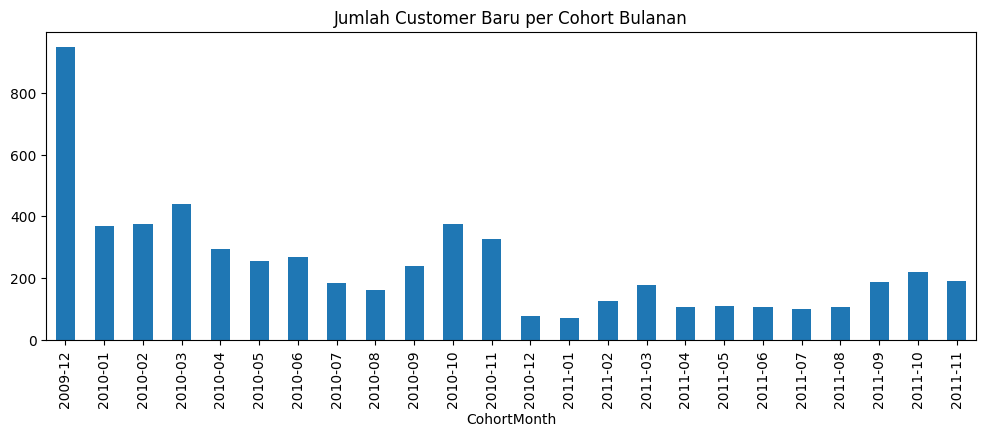

In [35]:
#Preview ukuran tiap cohort
cohort_size = invoice_table.groupby('CohortMonth')['Customer_ID'].nunique()
print("Jumlah customer baru per cohort bulanan:")
print(cohort_size)

cohort_size.plot(kind='bar', figsize=(12,4), title='Jumlah Customer Baru per Cohort Bulanan')

CATATAN LIMITASI: Cohort Des 2009 kemungkinan mengandung customer existing, bukan murni akuisis baru, karena itu adalah bulan pertama datase dimulai.

### SIMPAN DATA KE GDRIVE KU

In [36]:
from google.colab import drive
drive.mount('/content/drive')

# Buat folder khusus project (sekali saja, aman dijalankan berkali-kali)
import os
save_path = '/content/drive/MyDrive/Ecommerce_Retention_Project'
os.makedirs(save_path, exist_ok=True)

invoice_table.to_csv(f'{save_path}/invoice_table_with_cohort.csv', index=False)
customer_table.to_csv(f'{save_path}/customer_table.csv', index=False)
df_cancelled.to_csv(f'{save_path}/cancelled_transactions.csv', index=False)

print(f"Tersimpan permanen di: {save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tersimpan permanen di: /content/drive/MyDrive/Ecommerce_Retention_Project


# **STEP 5 RETENTION CALCULATION**

In [37]:
# Hitung jumlah unique customer per kombinasi CohortMonth x CohortIndex
cohort_data = invoice_table.groupby(['CohortMonth', 'CohortIndex'])['Customer_ID'].nunique().reset_index()

# Pivot: baris = CohortMonth, kolom = CohortIndex, isi = jumlah customer aktif
cohort_counts = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='Customer_ID')

print(cohort_counts.iloc[:6, :6])

CohortIndex      1      2      3      4      5      6
CohortMonth                                          
2009-12      951.0  333.0  317.0  404.0  360.0  342.0
2010-01      368.0   79.0  118.0  116.0  100.0  114.0
2010-02      375.0   88.0   85.0  110.0   92.0   74.0
2010-03      441.0   84.0  102.0  107.0  102.0   90.0
2010-04      294.0   56.0   56.0   47.0   54.0   65.0
2010-05      255.0   40.0   43.0   45.0   45.0   65.0


In [38]:
# Ukuran cohort = jumlah customer di CohortIndex 1 (bulan pertama, selalu 100%)
cohort_sizes = cohort_counts.iloc[:, 0]

# Retention rate = jumlah customer aktif di bulan ke-N / ukuran cohort awal
retention_matrix = cohort_counts.divide(cohort_sizes, axis=0)

# Format ke persen untuk dibaca
retention_matrix_pct = (retention_matrix * 100).round(1)

print(retention_matrix_pct.iloc[:6, :6])

CohortIndex      1     2     3     4     5     6
CohortMonth                                     
2009-12      100.0  35.0  33.3  42.5  37.9  36.0
2010-01      100.0  21.5  32.1  31.5  27.2  31.0
2010-02      100.0  23.5  22.7  29.3  24.5  19.7
2010-03      100.0  19.0  23.1  24.3  23.1  20.4
2010-04      100.0  19.0  19.0  16.0  18.4  22.1
2010-05      100.0  15.7  16.9  17.6  17.6  25.5


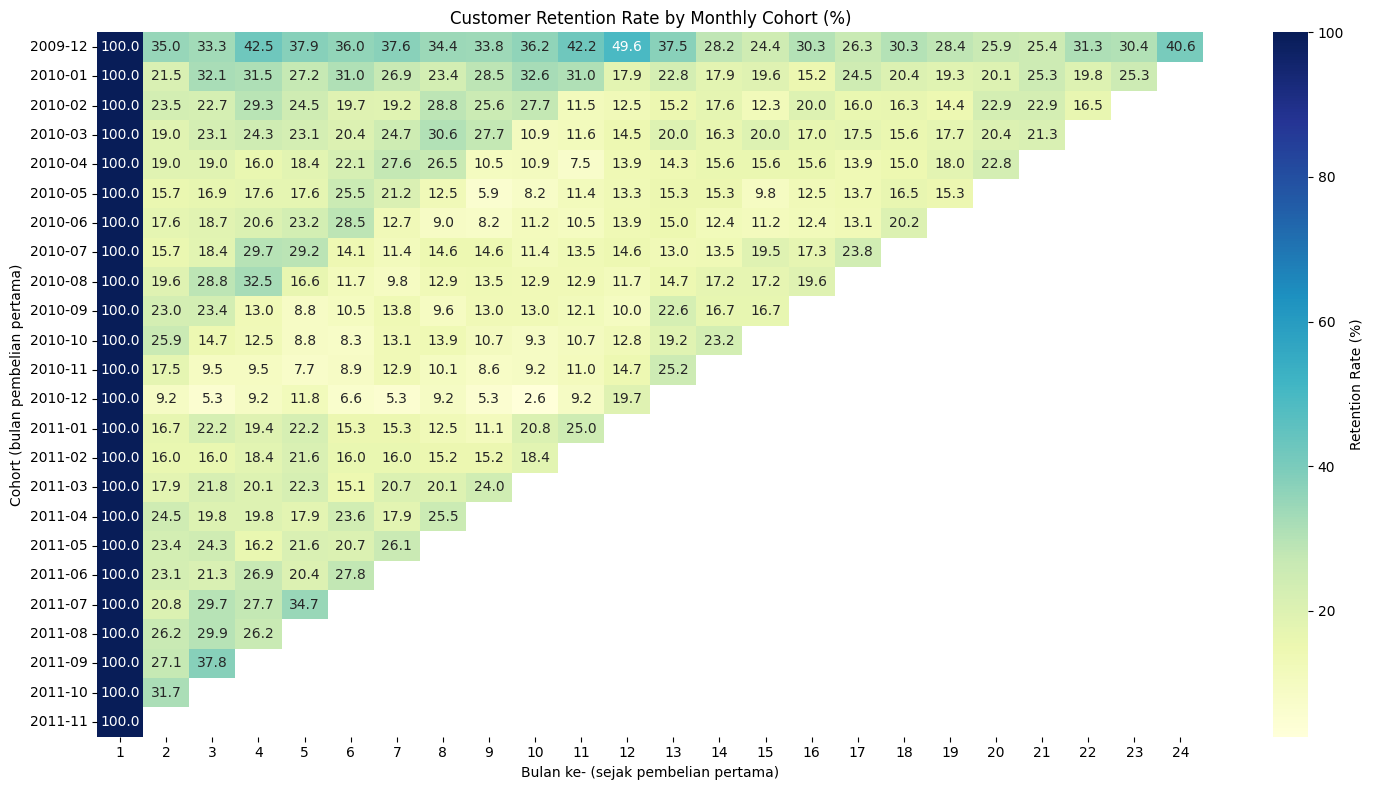

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
sns.heatmap(retention_matrix_pct, annot=True, fmt='.1f', cmap='YlGnBu',
            cbar_kws={'label': 'Retention Rate (%)'})
plt.title('Customer Retention Rate by Monthly Cohort (%)')
plt.xlabel('Bulan ke- (sejak pembelian pertama)')
plt.ylabel('Cohort (bulan pembelian pertama)')
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/retention_heatmap.png', dpi=150)
plt.show()

In [49]:
# Reset index supaya CohortMonth jadi kolom biasa, bukan index
retention_wide = retention_matrix_pct.reset_index()
retention_wide['CohortMonth'] = retention_wide['CohortMonth'].astype(str)  # ubah Period jadi text, biar aman dibaca Power BI

# Ubah dari wide (kolom 1,2,3...24) ke long format (1 baris per kombinasi CohortMonth-CohortIndex)
retention_long = retention_wide.melt(
    id_vars='CohortMonth',
    var_name='CohortIndex',
    value_name='RetentionRate'
)

# Buang baris yang NaN (cohort yang belum cukup umur untuk CohortIndex tertentu)
retention_long = retention_long.dropna(subset=['RetentionRate'])

# Pastikan tipe data benar
retention_long['CohortIndex'] = retention_long['CohortIndex'].astype(int)
retention_long['RetentionRate'] = retention_long['RetentionRate'].astype(float)

print(retention_long.head(10))
print(f"\nTotal baris: {len(retention_long)}")

# Simpan versi long format - INI yang dipakai di Power BI
# Buang CohortIndex=1 khusus untuk versi heatmap, karena nilainya selalu 100%
# dan merusak skala warna conditional formatting di Power BI
retention_long_for_heatmap = retention_long[retention_long['CohortIndex'] > 1]
retention_long_for_heatmap.to_csv(f'{DRIVE_PATH}/retention_matrix_long.csv', index=False)

print(f"Tersimpan versi untuk heatmap (tanpa kolom bulan 1): {len(retention_long_for_heatmap)} baris")

# Cohort sizes juga disamakan formatnya
cohort_sizes_df = cohort_sizes.reset_index()
cohort_sizes_df.columns = ['CohortMonth', 'CohortSize']
cohort_sizes_df['CohortMonth'] = cohort_sizes_df['CohortMonth'].astype(str)
cohort_sizes_df.to_csv(f'{DRIVE_PATH}/cohort_sizes.csv', index=False)

print(f"\nTersimpan: retention_matrix_long.csv & cohort_sizes.csv di {DRIVE_PATH}")

  CohortMonth  CohortIndex  RetentionRate
0     2009-12            1          100.0
1     2010-01            1          100.0
2     2010-02            1          100.0
3     2010-03            1          100.0
4     2010-04            1          100.0
5     2010-05            1          100.0
6     2010-06            1          100.0
7     2010-07            1          100.0
8     2010-08            1          100.0
9     2010-09            1          100.0

Total baris: 300
Tersimpan versi untuk heatmap (tanpa kolom bulan 1): 276 baris

Tersimpan: retention_matrix_long.csv & cohort_sizes.csv di /content/drive/MyDrive/Ecommerce_Retention_Project


# **Step 6: Exploratory Analysis**

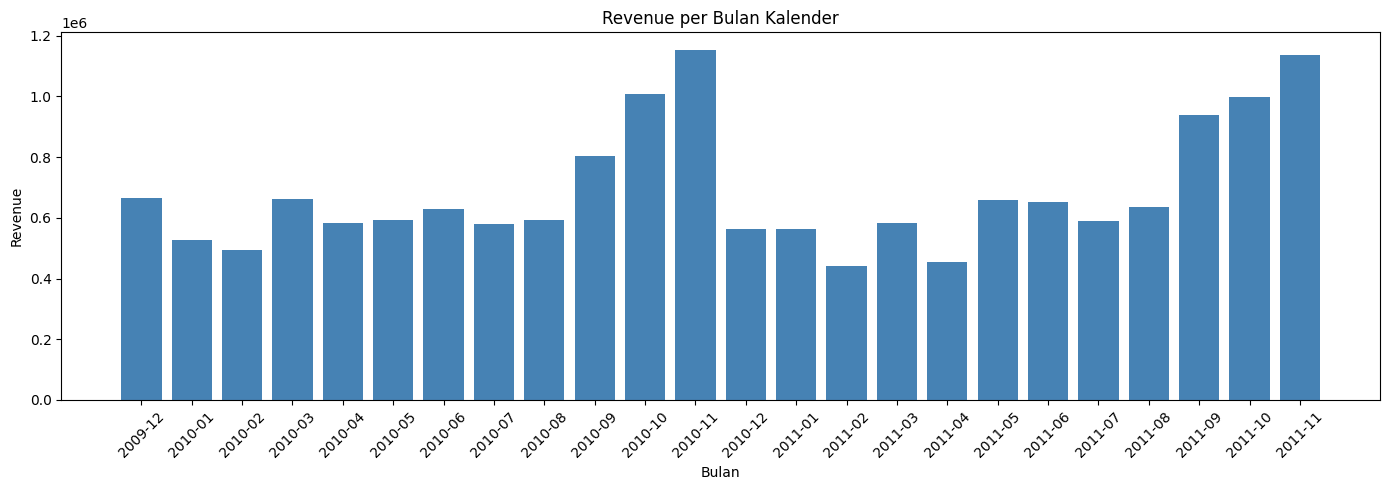

In [41]:
# Tren revenue & jumlah order per bulan kalender

monthly_trend = df_clean.groupby(df_clean['InvoiceDate'].dt.to_period('M')).agg(
    Revenue=('Revenue', 'sum'),
    Orders=('Invoice', 'nunique')
).reset_index()
monthly_trend['InvoiceDate'] = monthly_trend['InvoiceDate'].astype(str)

fig, ax1 = plt.subplots(figsize=(14,5))
ax1.bar(monthly_trend['InvoiceDate'], monthly_trend['Revenue'], color='steelblue')
ax1.set_ylabel('Revenue')
ax1.set_xlabel('Bulan')
plt.xticks(rotation=45)
plt.title('Revenue per Bulan Kalender')
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/monthly_revenue_trend.png', dpi=150)
plt.show()

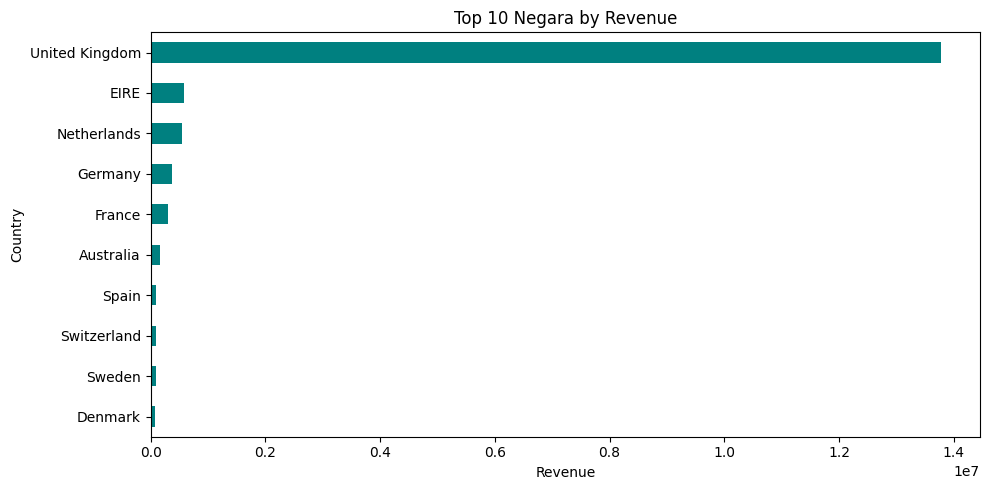

% Revenue dari United Kingdom: 83.5%


In [42]:
#Revenue & konsentrasi per Negara

country_revenue = df_clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
top10_country = country_revenue.head(10)

plt.figure(figsize=(10,5))
top10_country.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.xlabel('Revenue')
plt.title('Top 10 Negara by Revenue')
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/revenue_by_country.png', dpi=150)
plt.show()

uk_share = country_revenue['United Kingdom'] / country_revenue.sum()
print(f"% Revenue dari United Kingdom: {uk_share:.1%}")

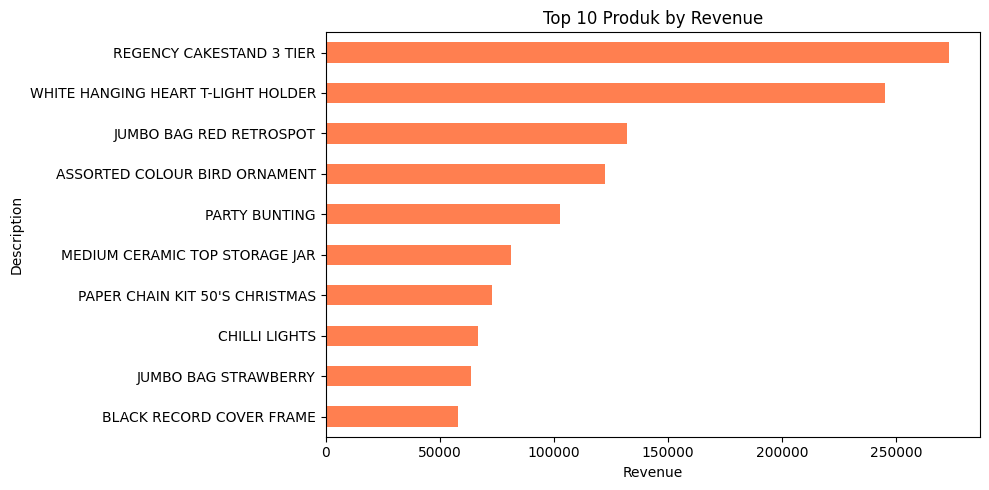

,Revenue
Description,
REGENCY CAKESTAND 3 TIER,273123.97
WHITE HANGING HEART T-LIGHT HOLDER,245052.22
JUMBO BAG RED RETROSPOT,132287.04
ASSORTED COLOUR BIRD ORNAMENT,122352.40
PARTY BUNTING,102818.08
MEDIUM CERAMIC TOP STORAGE JAR,81213.22
PAPER CHAIN KIT 50'S CHRISTMAS,72744.66
CHILLI LIGHTS,66967.88
JUMBO BAG STRAWBERRY,63562.59


In [43]:
#Produk terlaris by revenue
top_products = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
top_products.plot(kind='barh', color='coral')
plt.gca().invert_yaxis()
plt.xlabel('Revenue')
plt.title('Top 10 Produk by Revenue')
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/top_products.png', dpi=150)
plt.show()

top_products

In [44]:
exclude_desc = ['Manual', 'POSTAGE', 'DOTCOM POSTAGE', 'CARRIAGE']
top_products_clean = (df_clean[~df_clean['Description'].isin(exclude_desc)]
                       .groupby('Description')['Revenue'].sum()
                       .sort_values(ascending=False).head(10))
print(top_products_clean)

Description
REGENCY CAKESTAND 3 TIER              273123.97
WHITE HANGING HEART T-LIGHT HOLDER    245052.22
JUMBO BAG RED RETROSPOT               132287.04
ASSORTED COLOUR BIRD ORNAMENT         122352.40
PARTY BUNTING                         102818.08
MEDIUM CERAMIC TOP STORAGE JAR         81213.22
PAPER CHAIN KIT 50'S CHRISTMAS         72744.66
CHILLI LIGHTS                          66967.88
JUMBO BAG STRAWBERRY                   63562.59
BLACK RECORD COVER FRAME               58103.85
Name: Revenue, dtype: float64


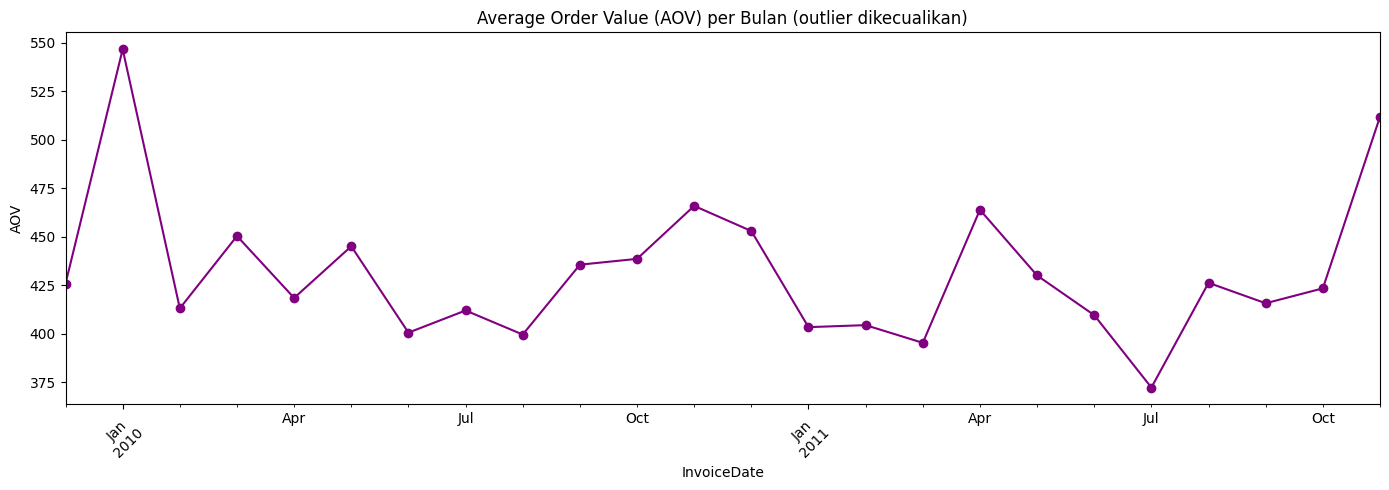

In [45]:
# Exclude outlier supaya AOV tidak bias oleh beberapa transaksi wholesale ekstrem
aov_trend = (invoice_table.merge(df_clean[['Invoice','is_outlier']].drop_duplicates(), on='Invoice', how='left')
             .loc[lambda x: x['is_outlier'] != True]
             .groupby(invoice_table['InvoiceDate'].dt.to_period('M'))['Revenue'].mean())

plt.figure(figsize=(14,5))
aov_trend.plot(kind='line', marker='o', color='purple')
plt.title('Average Order Value (AOV) per Bulan (outlier dikecualikan)')
plt.ylabel('AOV')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/aov_trend.png', dpi=150)
plt.show()

In [46]:
monthly_trend.to_csv(f'{DRIVE_PATH}/monthly_trend.csv', index=False)
country_revenue.to_csv(f'{DRIVE_PATH}/revenue_by_country.csv')
top_products_clean.to_csv(f'{DRIVE_PATH}/top_products.csv')

print("Semua file exploratory tersimpan di:", DRIVE_PATH)

Semua file exploratory tersimpan di: /content/drive/MyDrive/Ecommerce_Retention_Project


# **agregasi data cancelled_transactions**

In [48]:
# Load ulang data cancelled_transactions kalau variabelnya belum ada di memori
df_cancelled = pd.read_csv(f'{DRIVE_PATH}/cancelled_transactions.csv')

# Hitung nilai transaksi (Quantity sudah negatif untuk cancel, jadi Revenue otomatis negatif)
df_cancelled['Revenue'] = df_cancelled['Quantity'] * df_cancelled['Price']

# 1. Produk yang paling sering dibatalkan (by jumlah baris pembatalan)
# Keluarkan entri non-produk (adjustment admin, ongkir, diskon) supaya ranking murni produk fisik
exclude_desc = ['Manual', 'POSTAGE', 'DOTCOM POSTAGE', 'CARRIAGE', 'Discount', 'Adjustment', 'Bank Charges']

top_cancelled_products = (
    df_cancelled[~df_cancelled['Description'].isin(exclude_desc)]
    .groupby('Description')
    .agg(Times_Cancelled=('Invoice', 'count'), Total_Value=('Revenue', 'sum'))
    .sort_values('Times_Cancelled', ascending=False)
    .head(10)
    .reset_index()
)
print("Top 10 produk paling sering dibatalkan:")
print(top_cancelled_products)

# 2. Tren nilai pembatalan per bulan
df_cancelled['InvoiceDate'] = pd.to_datetime(df_cancelled['InvoiceDate'])
cancelled_monthly = (
    df_cancelled.groupby(df_cancelled['InvoiceDate'].dt.to_period('M'))
    .agg(Total_Cancelled_Value=('Revenue', 'sum'), N_Cancellations=('Invoice', 'nunique'))
    .reset_index()
)
cancelled_monthly['InvoiceDate'] = cancelled_monthly['InvoiceDate'].astype(str)
print("\nTren pembatalan per bulan:")
print(cancelled_monthly)

# 3. Ringkasan total (buat KPI card)
total_cancelled_value = df_cancelled['Revenue'].sum()
total_cancelled_orders = df_cancelled['Invoice'].nunique()
print(f"\nTotal nilai transaksi dibatalkan: {total_cancelled_value:,.2f}")
print(f"Total order dibatalkan: {total_cancelled_orders}")

# Simpan untuk Power BI
top_cancelled_products.to_csv(f'{DRIVE_PATH}/top_cancelled_products.csv', index=False)
cancelled_monthly.to_csv(f'{DRIVE_PATH}/cancelled_monthly.csv', index=False)

print(f"\nTersimpan di: {DRIVE_PATH}")

Top 10 produk paling sering dibatalkan:
                          Description  Times_Cancelled  Total_Value
0            REGENCY CAKESTAND 3 TIER              338    -16454.10
1        BAKING SET 9 PIECE RETROSPOT              208     -4043.05
2      STRAWBERRY CERAMIC TRINKET BOX              181      -922.59
3  WHITE HANGING HEART T-LIGHT HOLDER              132     -9366.45
4                 WHITE CHERRY LIGHTS              124     -6387.35
5            RED RETROSPOT CAKE STAND              106     -4262.95
6                  PINK CHERRY LIGHTS               86     -4021.35
7  WOOD 2 DRAWER CABINET WHITE FINISH               85     -1683.85
8            JAM MAKING SET WITH JARS               84      -991.75
9      SWEETHEART CERAMIC TRINKET BOX               73      -388.93

Tren pembatalan per bulan:
   InvoiceDate  Total_Cancelled_Value  N_Cancellations
0      2009-12              -23378.91              388
1      2010-01              -25366.16              285
2      2010-02     